# Etapa II · Tarea B: clustering con K-Means

**Objetivo:** agrupar los artículos por áreas y similitudes metodológicas, sin usar las
etiquetas durante el ajuste.

| | |
|---|---|
| **Pipeline** | texto normalizado → vectorizador → `TruncatedSVD` opcional → `Normalizer` → `KMeans` |
| **Sin etiquetas** | K-Means se ajusta solo con train; las etiquetas se usan después solo para ARI/NMI y contingencia |
| **Silhouette** | distancia coseno, en el espacio SVD+L2 |
| **Estabilidad** | 5 semillas y ARI entre particiones |
| **Experimentos** | K01--K16 |

In [1]:
%matplotlib inline

In [2]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
print("Raíz:", ROOT)


Raíz: /home/mrangello/Documentos/PracticaML


In [3]:
exp = pd.read_csv(ROOT / "results/etapa2/experiments.tsv", sep="\t",
                   dtype=str, keep_default_na=False)

def dev_macro_f1(row):
    return float(row["dev_metric"].split("macro_f1=")[1].split(";")[0])

def extra_dict(row):
    return dict(part.split("=", 1) for part in row["extra"].split("; "))

def get(exp_id):
    return exp[exp["experiment_id"] == exp_id].iloc[0]


## 1. Selección de k (K-1)

In [4]:
clu = exp[exp["task"] == "clustering"].copy()

def sil(row):
    return float(row["dev_metric"].split("=")[1])

k1 = clu[clu["block"] == "K-1"].sort_values("experiment_id")
rows = []
for _, row in k1.iterrows():
    extra = extra_dict(row)
    rows.append({
        "k": int(row["hyperparameters"].split("k=")[1].split(";")[0]),
        "Exp.": row["experiment_id"],
        "Silhouette train": round(float(extra["train_silhouette"]), 4),
        "Silhouette dev": round(sil(row), 4),
        "ARI dev": round(float(extra["ari_dev"]), 4),
        "Estabilidad": round(float(extra["stability_ari"].split("±")[0]), 4),
    })
display(pd.DataFrame(rows))

,k,Exp.,Silhouette train,Silhouette dev,ARI dev,Estabilidad
0,3,K01,0.0284,0.0651,0.2854,0.2671
1,4,K02,0.0301,0.0660,0.3755,0.2335
2,5,K03,0.0325,0.0609,0.3375,0.2228
3,6,K04,0.0353,0.0645,0.2954,0.2347
4,8,K05,0.0427,0.0664,0.2633,0.2123


El silhouette en dev es prácticamente plano (0.061--0.066) y la estabilidad es
moderada (0.21--0.27), típica de K-Means en texto. No hay un k que se separe por silhouette;
la interpretabilidad decide.

## 2. Ganadores por bloque y el problema del silhouette

In [5]:
winners = pd.DataFrame([
    ("K-1", "K01", 3, 0.0651, 0.2854),
    ("K-2", "K06", 3, 0.0986, 0.0217),
    ("K-3", "K08", 3, 0.1727, 0.0427),
    ("K-4", "K09", 3, 0.1873, 0.0349),
    ("K-5", "K11", 3, 0.2085, 0.0427),
    ("K-6", "K16", 3, 0.2085, 0.0427),
], columns=["Bloque", "Ganador", "k", "Silhouette dev", "ARI dev"])
display(winners)

,Bloque,Ganador,k,Silhouette dev,ARI dev
0,K-1,K01,3,0.0651,0.2854
1,K-2,K06,3,0.0986,0.0217
2,K-3,K08,3,0.1727,0.0427
3,K-4,K09,3,0.1873,0.0349
4,K-5,K11,3,0.2085,0.0427
5,K-6,K16,3,0.2085,0.0427


Los bloques K-2 a K-6 suben el silhouette hasta 0.209 (K16: N0, frecuencia,
bigramas, SVD 50), pero sus clusters separan **artefactos de formato** (números, LaTeX,
longitud) y su ARI es cercano a 0.04. El plan advierte que el silhouette solo se compara
dentro del mismo espacio de características; entre espacios distintos hay que usar la
interpretabilidad. Por eso **K16 no se eligió**.

## 3. Configuración final: K02

In [6]:
k02 = exp[exp["experiment_id"] == "K02"].iloc[0]
print("Configuración:", k02["normalization"], "·", k02["representation"],
      "·", k02["ngram_range"], "· SVD", k02["svd_components"])
print("Hiperparámetros:", k02["hyperparameters"])
print("Silhouette dev:", k02["dev_metric"])

Configuración: N2 · tfidf · (1,1) · SVD 100
Hiperparámetros: k=4; init=k-means++; n_init=10; max_iter=300; random_state=0
Silhouette dev: silhouette=0.0660


K02 usa k=4, N2, TF-IDF (1,1), SVD 100, `k-means++`, `n_init=10`, `max_iter=300`.
Dentro de su espacio, su silhouette dev (0.0660) está empatado con el máximo (0.0664) y sus
cuatro clusters son temáticos. Se reajustó con train+dev y se asignó test con `predict`:
silhouette test **0.0829**, ARI **0.3719**, NMI **0.4860**.

## 4. Clusters finales

In [7]:
summary = pd.read_csv(ROOT / "results/etapa2/cluster_summary.tsv", sep="\t")
display(summary)

,cluster_id,size,top_words,representative_document_ids
0,0,192,"training, task, language, token, datum, improve, prompt, target, base, reasoning","2610.00673,2609.23449"
1,1,156,"retrieval, evidence, item, recommendation, query, user, base, agent, language, search","2609.38473,2609.37574"
2,2,113,"video, image, visual, generation, scene, training, physical, benchmark, introduce, rep...","2609.40347,2610.00812"
3,3,39,"parameter, training, learn, attention, cost, scale, noise, long, introduce, feature","2610.00545,2609.39855"


In [8]:
assign = pd.read_csv(ROOT / "results/etapa2/clustering_results.tsv", sep="\t",
                     dtype=str, keep_default_na=False)
display(pd.crosstab(assign["cluster_id"], assign["split"]))

split,dev,test,train
cluster_id,,,
0,34,30,128
1,16,25,115
2,17,14,82
3,8,6,25


## 5. Contingencia en test

In [9]:
cont = pd.read_csv(ROOT / "results/etapa2/cluster_contingency_test.tsv",
                    sep="\t", index_col=0)
display(cont)

,0,1,2,3
gold,,,,
cs.CL,13,5,1,0
cs.CV,4,2,13,0
cs.IR,1,18,0,0
cs.LG,12,0,0,6


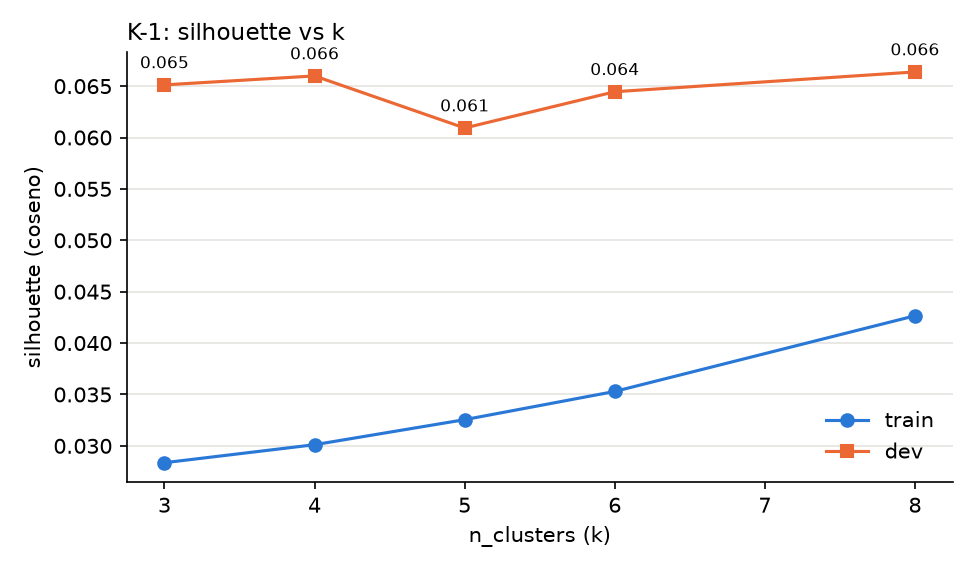

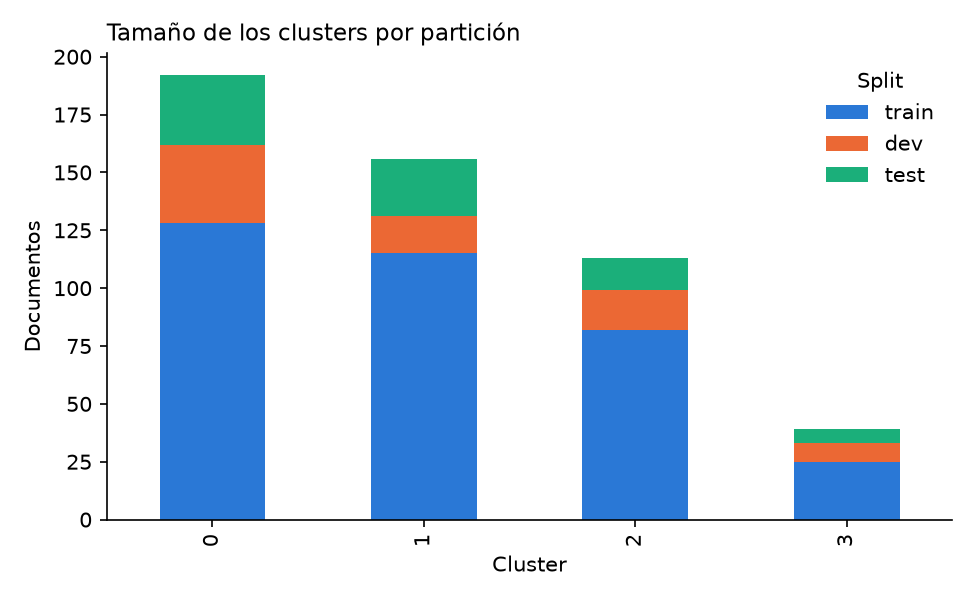

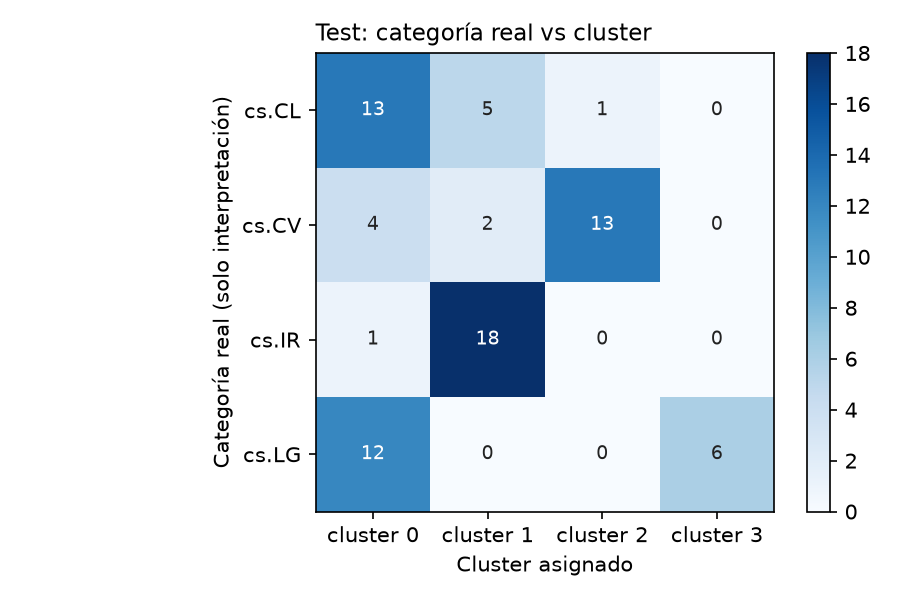

In [10]:
display(Image(filename=str(ROOT / "results/etapa2/figures/clustering_silhouette_vs_k.png")))
display(Image(filename=str(ROOT / "results/etapa2/figures/clustering_sizes.png")))
display(Image(filename=str(ROOT / "results/etapa2/figures/clustering_contingency_test.png")))

## 6. Interpretación

- **Cluster 0 (192):** `training, task, language, token, datum, prompt...` → NLP/agentes;
  mezcla 13 `cs.CL` y 12 `cs.LG`, la misma frontera que confunde al clasificador.
- **Cluster 1 (156):** `retrieval, evidence, item, recommendation, query...` →
  IR/recomendación; captura 18 de 19 `cs.IR`.
- **Cluster 2 (113):** `video, image, visual, generation, scene...` → visión/vídeo;
  captura 13 de 19 `cs.CV`.
- **Cluster 3 (39):** `parameter, training, learn, attention, scale...` → ML general;
  concentra 6 de 18 `cs.LG`. Es pequeño, pero interpretable.
- **ARI/NMI** en test (0.372/0.486) indican una alineación moderada con las categorías,
  razonable para un método no supervisado.
- **Limitaciones:** silhouette bajo (0.083), estabilidad moderada (0.234) y cluster 3
  pequeño. No se fuerza k=4: surgió de la comparación de K-1.